In [16]:
# --- Parallelization Workflow ---
# history and achievements run concurrently from START, then converge at article node
# Both parallel branches must complete before generate_article can execute
from typing import Annotated, List, Literal, Optional, TypedDict,NotRequired
from pydantic import BaseModel, Field, field_validator, ValidationError
from operator import add
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END
from langgraph.graph.state import CompiledStateGraph
from IPython.display import Image, display
import re

# Google
from langchain_google_genai import ChatGoogleGenerativeAI

# HuggingFace
# from langchain_huggingface.embeddings import HuggingFaceEndpointEmbeddings
# from langchain_huggingface import ChatHuggingFace, HuggingFaceEndpoint

# Cohere
from langchain_cohere import CohereEmbeddings

# Prompts
from langchain.prompts import PromptTemplate
from langchain_core.messages import BaseMessage
from langchain_core.tools import tool

# Others
import os
from dotenv import load_dotenv
# # LangSmith
# import uuid
# from langchain_core.tracers.context import collect_runs
# from langchain_core.tracers.langchain import wait_for_all_tracers
# from langsmith import Client
# from langchain.callbacks.tracers import LangChainTracer

In [17]:
from dotenv import load_dotenv

# Provide the filename as a string
load_dotenv('.env')

True

In [18]:
# loadding Google token
GOOGLE_API_KEY = os.getenv("GOOGLE_AI_STUDIO_GENERATIVE_MODEL_API_KEY")
# using Google from langchain
google_llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.1,
    max_output_tokens=4096,
    api_key=GOOGLE_API_KEY
)

## **Pydantic: Validation Logic for each node**

In [37]:
# Pydantic: Validate external input
class ScientistInput(BaseModel):
    scientist: str = Field( min_length=3,max_length=100, 
    description="The name of the scientist"
    )

    @field_validator("scientist")
    def validate_scientist(cls, value):
        value = value.strip()
        if not re.search("[a-zA-Z]", value):
            raise ValueError("Scientist name must contain letters.")
        return value.strip()

In [20]:
# Pydantic: Validate LLM outputs
class ScientistHistoryOutput(BaseModel):
    history: str = Field(description="The history of the scientist")

class ScientistAchievementsOutput(BaseModel):
    achievements: list[str] = Field(description="Five major achievements of the scientist")

class ScientistArticleOutput(BaseModel):
    article: str = Field(description="Detailed article about the scientist")

class RefinedArticleOutput(BaseModel):
    refined_article: str = Field(description="Refined article about the scientist under 1000 words")

In [21]:
# Structured LLMs 
history_llm = google_llm.with_structured_output(ScientistHistoryOutput)
achievements_llm = google_llm.with_structured_output(ScientistAchievementsOutput)
article_llm = google_llm.with_structured_output(ScientistArticleOutput)
refined_article_llm = google_llm.with_structured_output(RefinedArticleOutput)

## **Define Graph State**

In [22]:
# Graph State
class State(TypedDict):
    scientist: str 
    history: NotRequired[str]
    achievements: NotRequired[list[str]]
    article: NotRequired[str]
    refined_article: NotRequired[str] # or NotRequired[Optional[str]]

## **Defining the Nodes**

In [23]:
# Defining the nodes
def generate_history(state:State):
    # Prompt to get the scientist's information
    prompt = PromptTemplate.from_template(
    "Provide a brief history of {scientist}."
    )
    
    scientist = {"scientist": state["scientist"]}
    history_chain = prompt | history_llm
    response = history_chain.invoke(scientist) # or  response: ScientistHistoryOutput = history_chain.invoke(scientist)

    # Returning the response as a dictionary with the key "history"
    # return {"history": response.content}
    # changes to this due to structured output, we can access the history attribute directly
    return {"history": response.history}

In [24]:
# Defining the nodes
def generate_achievements(state:State):
    # Prompt to get the scientist's information
    prompt = PromptTemplate.from_template(
    """Provide 5 top achievements of {scientist} in bullet points.
    Example:
    - Achievement 1
    - Achievement 2
    - Achievement 3
    - Achievement 4
    - Achievement 5
    """
    )
    
    scientist = {"scientist": state["scientist"]}
    achievement_chain = prompt | achievements_llm
    response = achievement_chain.invoke(scientist)

    achievements_list_text = "\n".join([
        f"- {achievement}" for achievement in response.achievements
    ])
    return {"achievements": achievements_list_text}

In [ ]:
# Defining the nodes
def generate_article(state:State):
    # Prompt to get the scientist's information
    prompt = PromptTemplate.from_template(
    """Provide an in depth article about {scientist} based on the following information:
    History: {history}
    Achievements: {achievements}
    Final Article must be in Markdown format with different sections. For example;
    ## **Title**

    ### **History**

    ### **Achievements**

    ### **Main Contributions**

    ## **Conclusion**

    This is just an example you can modify
    You must give the article in Markdown format
    """
    )
    
    information_data = {"scientist": state["scientist"], 
                        "history": state["history"], 
                        "achievements": state["achievements"] 
                        }
    article_chain = prompt | article_llm
    response = article_chain.invoke(information_data)

    # Returning the response as a dictionary with the key "article"
    return {"article": response.article}

In [ ]:
# Defining the nodes
def generate_refined_article(state:State):
    # Prompt to get the scientist's information
    # Safely retrieve 'article' using .get() to prevent KeyError
    generated_article = state.get("article", "")
    
    if not generated_article:
        return {"refined_article": "Error: Article was not generated properly."}

    article_length = len(generated_article.split())
    if article_length > 1000:
        prompt = PromptTemplate.from_template(
        """Summarise the following article about {scientist} in less than 1000 words from given article\n{article}.\n
        It should be concise and clear, and should not lose the main points of the article.
        Final Article must be in Markdown format with different sections. For example;
        ## **Title**

        ### **History**

        ### **Achievements**

        ### **Main Contributions**
        
        ## **Conclusion**

        This is just an example you can modify
        You must give the article in Markdown format
        """
        )
        refined_article_data = {"scientist": state["scientist"], "article": generated_article}
        refined_article_chain = prompt | refined_article_llm
        response = refined_article_chain.invoke(refined_article_data)

        # Returning the response as a dictionary with the key "refined_article"
        return {"refined_article": response.refined_article}
    else:
        print("Initial article is already under 1000 words. No refinement needed.")
        return {"refined_article": generated_article}

## **Building the Graph**

In [27]:
# Build the parallelization workflow graph
# Two edges from START fork history and achievements into parallel execution
workflow = StateGraph(State)

# Registering the nodes
workflow.add_node("generate_history", generate_history)
workflow.add_node("generate_achievements", generate_achievements)
workflow.add_node("generate_article", generate_article)
workflow.add_node("generate_refined_article", generate_refined_article)

# Routing Logic for parallelization
workflow.add_edge(START, "generate_history")
workflow.add_edge(START, "generate_achievements")
workflow.add_edge("generate_history", "generate_article")
workflow.add_edge("generate_achievements", "generate_article")
workflow.add_edge("generate_article", "generate_refined_article")
workflow.add_edge("generate_refined_article", END)

graph = workflow.compile()

In [28]:
# Renders the LangGraph workflow as a Mermaid diagram
def graph_visualiser(graph):
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception as e:
        print(e)

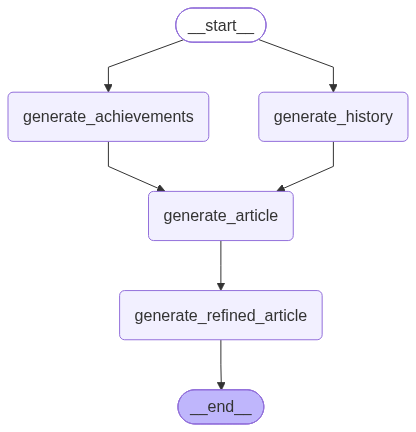

In [29]:
graph_visualiser(graph)

In [30]:
try:

    validated = ScientistInput.model_validate(
                {
                "scientist": "Isaac Newton"
                }
)

except ValidationError as e:
    print(e.errors()[0]["msg"])

In [38]:
try:
    validated_wrong = ScientistInput.model_validate(
        {
            "scientist": "ka"
        }
    )

except ValidationError as e:
    print(e.errors()[0]["msg"])

String should have at least 3 characters


In [ ]:
intial_state: State = {
    "scientist": validated.scientist
}

results = graph.invoke(intial_state)

Initial article is already under 1000 words. No refinement needed.


In [40]:
print(list(results.keys()))

['scientist', 'history', 'achievements', 'article', 'refined_article']


In [41]:
print(results["achievements"].strip())

- Developed the laws of motion and universal gravitation
- Invented calculus
- Made significant contributions to optics, including the theory of color
- Built the first reflecting telescope
- Formulated the binomial theorem


In [42]:
print(results["article"].strip())

Isaac Newton (1642-1727) was an English physicist, mathematician, astronomer, natural philosopher, alchemist, and theologian, widely regarded as one of the most influential scientists of all time and a key figure in the scientific revolution.

Newton's achievements are vast and profoundly shaped our understanding of the universe. He developed the laws of motion and universal gravitation, which laid the foundation for classical mechanics and explained the movement of celestial bodies as well as objects on Earth. His groundbreaking work, "Philosophiæ Naturalis Principia Mathematica" (Mathematical Principles of Natural Philosophy), published in 1687, is considered one of the most important scientific books ever written.

In mathematics, Newton is credited with inventing calculus (independently developed by Gottfried Wilhelm Leibniz), a powerful mathematical tool essential for understanding change and motion. He also formulated the binomial theorem, which provides a formula for expanding p

In [43]:
print(results["refined_article"].strip())

Isaac Newton (1642-1727) was an English physicist, mathematician, astronomer, natural philosopher, alchemist, and theologian, widely regarded as one of the most influential scientists of all time and a key figure in the scientific revolution.

Newton's achievements are vast and profoundly shaped our understanding of the universe. He developed the laws of motion and universal gravitation, which laid the foundation for classical mechanics and explained the movement of celestial bodies as well as objects on Earth. His groundbreaking work, "Philosophiæ Naturalis Principia Mathematica" (Mathematical Principles of Natural Philosophy), published in 1687, is considered one of the most important scientific books ever written.

In mathematics, Newton is credited with inventing calculus (independently developed by Gottfried Wilhelm Leibniz), a powerful mathematical tool essential for understanding change and motion. He also formulated the binomial theorem, which provides a formula for expanding p